# imports + config

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('inline')
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from pathlib import Path
from scipy import stats
from sklearn.linear_model imae_rmse_comparisonmport LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap
warnings.filterwarnings('ignore')

DEVICE       = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_ROOT   = Path('/content/drive/MyDrive/uav_thesis/model_outputs/v2')
ENRICHED_DIR = MODEL_ROOT / 'v3b/07_enriched_parquets'
OUT_DIR      = MODEL_ROOT / 'v3b/08_anomaly_regression'
PLOT_DIR     = OUT_DIR / 'plots'
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

FOLDS       = [f'fold_{i:02d}' for i in range(1, 6)]
TARGET      = 'target_energy_next_60s_wh'
OUTPUT_ROOT = Path('/content/drive/MyDrive/uav_thesis/processed_10hz/v2')

print(f'Device: {DEVICE}')
print(f'Enriched dir exists: {ENRICHED_DIR.exists()}')

Device: cuda
Enriched dir exists: True


In [3]:
print(f'Enriched dir exists: {ENRICHED_DIR.exists()}')
print(f'Out dir: {OUT_DIR}')

Enriched dir exists: True
Out dir: /content/drive/MyDrive/uav_thesis/model_outputs/v2/v3b/08_anomaly_regression


# load enriched parquets

In [4]:
from pathlib import Path
MODEL_ROOT = Path('/content/drive/MyDrive/uav_thesis/model_outputs/v2')

v3b = MODEL_ROOT / 'v3b'
if v3b.exists():
    for p in sorted(v3b.rglob('*')):
        if p.is_file():
            print(p.relative_to(MODEL_ROOT))
else:
    print('v3b folder does not exist')

v3b/07_anomaly_enriched/all_train_oof_scores.parquet
v3b/07_anomaly_enriched/anomaly_score_distribution.png
v3b/07_anomaly_enriched/anomaly_score_global_summary.csv
v3b/07_anomaly_enriched/anomaly_score_per_fold_split_summary.csv
v3b/07_anomaly_enriched/anomaly_score_per_fold_summary.csv
v3b/07_anomaly_enriched/norm_scaler_fold_01.joblib
v3b/07_anomaly_enriched/norm_scaler_fold_02.joblib
v3b/07_anomaly_enriched/norm_scaler_fold_03.joblib
v3b/07_anomaly_enriched/norm_scaler_fold_04.joblib
v3b/07_anomaly_enriched/norm_scaler_fold_05.joblib
v3b/07_anomaly_enriched/oof_and_test_anomaly_scores.parquet
v3b/07_anomaly_enriched/separation_ratio_per_fold.png
v3b/07_anomaly_enriched/train_oof_scores_fold_01.parquet
v3b/07_anomaly_enriched/train_oof_scores_fold_02.parquet
v3b/07_anomaly_enriched/train_oof_scores_fold_03.parquet
v3b/07_anomaly_enriched/train_oof_scores_fold_04.parquet
v3b/07_anomaly_enriched/train_oof_scores_fold_05.parquet
v3b/07_enriched_parquets/test_enriched_fold_01.parquet
v3

In [5]:
enriched = {}
for fold in FOLDS:
    fold_dir = OUTPUT_ROOT / fold
    with open(fold_dir / f'feature_cols_{fold}.json') as f:
        feature_cols = json.load(f)
    enriched[fold] = {
        'feature_cols': feature_cols,
        'train': pd.read_parquet(ENRICHED_DIR / f'train_enriched_{fold}.parquet'),
        'val':   pd.read_parquet(ENRICHED_DIR / f'val_enriched_{fold}.parquet'),
        'test':  pd.read_parquet(ENRICHED_DIR / f'test_enriched_{fold}.parquet'),
    }
    tr = enriched[fold]['train']
    te = enriched[fold]['test']
    print(f'{fold} | train={len(tr)} val={len(enriched[fold]["val"])} '
          f'test={len(te)} | features={len(feature_cols)} | '
          f'anomaly_score nulls={te["anomaly_score"].isna().sum()}')

fold_01 | train=665216 val=110878 test=190831 | features=16 | anomaly_score nulls=0
fold_02 | train=643038 val=105335 test=218552 | features=16 | anomaly_score nulls=0
fold_03 | train=677953 val=105412 test=183560 | features=16 | anomaly_score nulls=0
fold_04 | train=671181 val=114458 test=181286 | features=16 | anomaly_score nulls=0
fold_05 | train=648120 val=126109 test=192696 | features=16 | anomaly_score nulls=0


In [6]:
for fold in FOLDS:
    tr = enriched[fold]['train']
    pct_zero = (tr['anomaly_score'] == 0).mean()
    print(f'{fold} | zeros={pct_zero:.1%} | '
          f'min={tr["anomaly_score"].min():.4f} | '
          f'max={tr["anomaly_score"].max():.4f}')

fold_01 | zeros=0.6% | min=0.0000 | max=1.0000
fold_02 | zeros=0.6% | min=0.0000 | max=1.0000
fold_03 | zeros=0.6% | min=0.0000 | max=1.0000
fold_04 | zeros=0.6% | min=0.0000 | max=1.0000
fold_05 | zeros=0.5% | min=0.0000 | max=1.0000


In [7]:
for fold in FOLDS:
    tr = enriched[fold]['train']
    print(f'{fold} | zeros={(tr["anomaly_score"]==0).mean():.1%} | '
          f'min={tr["anomaly_score"].min():.4f} | '
          f'max={tr["anomaly_score"].max():.4f}')

fold_01 | zeros=0.6% | min=0.0000 | max=1.0000
fold_02 | zeros=0.6% | min=0.0000 | max=1.0000
fold_03 | zeros=0.6% | min=0.0000 | max=1.0000
fold_04 | zeros=0.6% | min=0.0000 | max=1.0000
fold_05 | zeros=0.5% | min=0.0000 | max=1.0000


# helper functions

In [8]:
def get_Xy(df, feature_cols, use_anomaly):
    cols = feature_cols + (['anomaly_score'] if use_anomaly else [])
    return df[cols].values.astype(np.float32), df[TARGET].values.astype(np.float32)

def compute_metrics(y_true, y_pred, mean_power_w=None):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mask = y_true > 0.01
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    rft  = (mae / mean_power_w * 3600) if mean_power_w else None
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape, 'RFT_err_s': rft}

def wilcoxon_test(mae_baseline, mae_with):
    # one-sided: does +anomaly reduce MAE?
    diffs = np.array(mae_baseline) - np.array(mae_with)
    if np.all(diffs == 0):
        return np.nan, np.nan
    stat, p = stats.wilcoxon(diffs, alternative='greater')
    return stat, p

# tree baseline models (LR, RF, XGBoost)

In [9]:
tree_results = []

for fold in FOLDS:
    fc   = enriched[fold]['feature_cols']
    df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
    df_va = enriched[fold]['val']
    df_te = enriched[fold]['test']
    mean_pw = df_te['power_w'].mean() if 'power_w' in df_te.columns else None

    models_cfg = {
        'LinearRegression': LinearRegression(),
        'RandomForest': RandomForestRegressor(
            n_estimators=300, max_depth=15, min_samples_leaf=10,
            max_features=0.5, n_jobs=-1, random_state=42),
        'XGBoost': XGBRegressor(
            n_estimators=1000, max_depth=5, learning_rate=0.01,
            min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
            early_stopping_rounds=50, random_state=42, verbosity=0, n_jobs=-1),
    }

    for model_name, mdl in models_cfg.items():
        for use_anomaly in [False, True]:
            X_tr, y_tr = get_Xy(df_tr, fc, use_anomaly)
            X_te, y_te = get_Xy(df_te, fc, use_anomaly)

            if model_name == 'XGBoost':
                X_va, y_va = get_Xy(df_va, fc, use_anomaly)
                mdl.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
            else:
                mdl.fit(X_tr, y_tr)

            preds = mdl.predict(X_te)
            m = compute_metrics(y_te, preds, mean_pw)

            # subgroup MAE
            normal_mask   = df_te['dataset_label'] == 'normal'
            abnormal_mask = df_te['dataset_label'] == 'abnormal'
            m['MAE_normal']   = mean_absolute_error(y_te[normal_mask],   preds[normal_mask])   if normal_mask.any()   else np.nan
            m['MAE_abnormal'] = mean_absolute_error(y_te[abnormal_mask], preds[abnormal_mask]) if abnormal_mask.any() else np.nan

            m.update({'fold': fold, 'model': model_name,
                      'condition': 'with_anomaly' if use_anomaly else 'baseline'})
            tree_results.append(m)
            print(f'{fold} | {model_name:18s} | {"w/ anom" if use_anomaly else "baseline":10s} | '
                  f'MAE={m["MAE"]:.4f} RMSE={m["RMSE"]:.4f} R2={m["R2"]:.3f} '
                  f'MAPE={m["MAPE"]:.1f}% RFT={m["RFT_err_s"]:.1f}s')

df_tree = pd.DataFrame(tree_results)
df_tree.to_parquet(OUT_DIR / 'tree_model_results.parquet', index=False)

fold_01 | LinearRegression   | baseline   | MAE=0.4629 RMSE=0.7937 R2=0.851 MAPE=401.6% RFT=10050.3s
fold_01 | LinearRegression   | w/ anom    | MAE=0.4625 RMSE=0.7932 R2=0.851 MAPE=400.9% RFT=10042.7s
fold_01 | RandomForest       | baseline   | MAE=0.4138 RMSE=0.8825 R2=0.816 MAPE=137.7% RFT=8984.2s
fold_01 | RandomForest       | w/ anom    | MAE=0.5226 RMSE=1.0815 R2=0.723 MAPE=203.2% RFT=11346.7s
fold_01 | XGBoost            | baseline   | MAE=0.4074 RMSE=0.8833 R2=0.816 MAPE=152.0% RFT=8845.8s
fold_01 | XGBoost            | w/ anom    | MAE=0.4818 RMSE=0.9888 R2=0.769 MAPE=146.6% RFT=10462.6s
fold_02 | LinearRegression   | baseline   | MAE=0.7343 RMSE=1.8396 R2=0.896 MAPE=74.0% RFT=3021.1s
fold_02 | LinearRegression   | w/ anom    | MAE=0.7340 RMSE=1.8392 R2=0.896 MAPE=73.9% RFT=3019.6s
fold_02 | RandomForest       | baseline   | MAE=1.1876 RMSE=3.3739 R2=0.649 MAPE=149.4% RFT=4885.8s
fold_02 | RandomForest       | w/ anom    | MAE=1.2495 RMSE=3.2859 R2=0.667 MAPE=199.7% RFT=5140.5

# LSTM and BiLSTM architecture

In [10]:
import gc
import torch
torch.cuda.empty_cache()
gc.collect()
print(f'GPU free: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB')

GPU free: 15.53 GB


In [11]:
class LSTMRegressor(nn.Module):
    def __init__(self, n_features, hidden=128, layers=2, dropout=0.2, bidirectional=False):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers,
                            dropout=dropout, batch_first=True,
                            bidirectional=bidirectional)
        fc_in = hidden * 2 if bidirectional else hidden
        self.fc = nn.Sequential(
            nn.Linear(fc_in, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


def make_sequences(df, feature_cols, target, window=50, stride=10):
    X_list, y_list = [], []
    for _, grp in df.groupby('log_id', sort=False):
        vals = grp[feature_cols].values.astype(np.float32)
        tgt  = grp[target].values.astype(np.float32)
        for i in range(0, len(vals) - window + 1, stride):
            X_list.append(vals[i:i+window])
            y_list.append(tgt[i + window - 1])
    return np.array(X_list), np.array(y_list)


def train_lstm(model, X_tr, y_tr, X_va, y_va,
               lr=1e-3, epochs=100, patience=10, batch=256):
    torch.cuda.empty_cache()
    gc.collect()
    opt      = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn  = nn.MSELoss()
    tr_ds    = TensorDataset(torch.tensor(X_tr), torch.tensor(y_tr))
    tr_dl    = DataLoader(tr_ds, batch_size=batch, shuffle=True)
    X_va_t   = torch.tensor(X_va).to(DEVICE)
    y_va_t   = torch.tensor(y_va).to(DEVICE)

    best_val, patience_ctr, best_state = np.inf, 0, None
    for epoch in range(epochs):
        model.train()
        for xb, yb in tr_dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_va_t), y_va_t).item()
        if val_loss < best_val:
            best_val    = val_loss
            best_state  = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                break
    model.load_state_dict(best_state)
    return model


def predict_lstm(model, X, batch=512):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb = torch.tensor(X[i:i+batch]).to(DEVICE)
            preds.append(model(xb).cpu().numpy())
    return np.concatenate(preds)

# run LSTM and BiLSTM

In [12]:
WINDOW, STRIDE = 50, 10
seq_results = []

for fold in FOLDS:
    fc      = enriched[fold]['feature_cols']
    df_tr   = enriched[fold]['train']
    df_va   = enriched[fold]['val']
    df_te   = enriched[fold]['test']
    mean_pw = df_te['power_w'].mean() if 'power_w' in df_te.columns else None

    for use_anomaly in [False, True]:
        cols   = fc + (['anomaly_score'] if use_anomaly else [])
        n_feat = len(cols)

        X_tr, y_tr = make_sequences(df_tr, cols, TARGET, WINDOW, STRIDE)
        X_va, y_va = make_sequences(df_va, cols, TARGET, WINDOW, STRIDE)
        X_te, y_te = make_sequences(df_te, cols, TARGET, WINDOW, STRIDE)

        # rebuild label masks aligned to sequence windows
        te_idx = []
        for _, grp in df_te.groupby('log_id', sort=False):
            n = len(grp)
            for i in range(0, n - WINDOW + 1, STRIDE):
                te_idx.append(grp.index[i + WINDOW - 1])
        te_labels = df_te.loc[te_idx, 'dataset_label'].values
        norm_seq  = te_labels == 'normal'
        abn_seq   = te_labels == 'abnormal'

        for arch, bidir in [('LSTM', False), ('BiLSTM', True)]:

            # ── checkpoint skip ──
            ckpt = OUT_DIR / f'{arch.lower()}_{fold}_{"anom" if use_anomaly else "base"}.pt'
            if ckpt.exists():
                print(f'  Skipping {arch} {fold} {"anom" if use_anomaly else "base"} — checkpoint exists')
                continue

            print(f'{fold} | {arch} | {"w/ anom" if use_anomaly else "baseline"} ...', end=' ')
            model = LSTMRegressor(n_feat, hidden=128, layers=2,
                                  dropout=0.2, bidirectional=bidir).to(DEVICE)
            model = train_lstm(model, X_tr, y_tr, X_va, y_va,
                               lr=1e-3, epochs=100, patience=10, batch=256)
            preds = predict_lstm(model, X_te)
            m = compute_metrics(y_te, preds, mean_pw)
            m['MAE_normal']   = mean_absolute_error(y_te[norm_seq], preds[norm_seq]) if norm_seq.any() else np.nan
            m['MAE_abnormal'] = mean_absolute_error(y_te[abn_seq],  preds[abn_seq])  if abn_seq.any()  else np.nan
            m.update({'fold': fold, 'model': arch,
                      'condition': 'with_anomaly' if use_anomaly else 'baseline'})
            seq_results.append(m)

            # save weights + partial results
            torch.save(model.state_dict(), ckpt)
            pd.DataFrame(seq_results).to_parquet(OUT_DIR / 'seq_results_partial.parquet', index=False)
            print(f'MAE={m["MAE"]:.4f} RMSE={m["RMSE"]:.4f} R2={m["R2"]:.3f}')

df_seq = pd.DataFrame(seq_results)
df_seq.to_parquet(OUT_DIR / 'seq_model_results.parquet', index=False)

fold_01 | LSTM | baseline ... MAE=0.3665 RMSE=0.8315 R2=0.837
fold_01 | BiLSTM | baseline ... MAE=0.4112 RMSE=0.9720 R2=0.777
fold_01 | LSTM | w/ anom ... MAE=0.3421 RMSE=0.8117 R2=0.844
fold_01 | BiLSTM | w/ anom ... MAE=0.5289 RMSE=1.1341 R2=0.696
fold_02 | LSTM | baseline ... MAE=0.9596 RMSE=2.5910 R2=0.794
fold_02 | BiLSTM | baseline ... MAE=1.1416 RMSE=2.8181 R2=0.756
fold_02 | LSTM | w/ anom ... MAE=0.9273 RMSE=2.3675 R2=0.828
fold_02 | BiLSTM | w/ anom ... MAE=0.9718 RMSE=2.7567 R2=0.767
fold_03 | LSTM | baseline ... MAE=0.4465 RMSE=1.0838 R2=0.911
fold_03 | BiLSTM | baseline ... MAE=0.4769 RMSE=0.9829 R2=0.927
fold_03 | LSTM | w/ anom ... MAE=0.6084 RMSE=1.4810 R2=0.834
fold_03 | BiLSTM | w/ anom ... MAE=0.4270 RMSE=0.9326 R2=0.934
fold_04 | LSTM | baseline ... MAE=0.2372 RMSE=0.3794 R2=0.897
fold_04 | BiLSTM | baseline ... MAE=0.3723 RMSE=0.7141 R2=0.636
fold_04 | LSTM | w/ anom ... MAE=0.2100 RMSE=0.3610 R2=0.907
fold_04 | BiLSTM | w/ anom ... MAE=0.2968 RMSE=0.5091 R2=0.815


# combine results + Wilcoxon test

In [13]:
df_all = pd.concat([df_tree, df_seq], ignore_index=True)

print('=== Mean ± std across 5 folds ===\n')
summary_rows = []
for model in ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']:
    for cond in ['baseline', 'with_anomaly']:
        sub = df_all[(df_all['model'] == model) & (df_all['condition'] == cond)]
        if sub.empty:
            continue
        row = {'model': model, 'condition': cond}
        for col in ['MAE', 'RMSE', 'R2', 'MAPE', 'RFT_err_s',
                    'MAE_normal', 'MAE_abnormal']:
            row[f'{col}_mean'] = sub[col].mean()
            row[f'{col}_std']  = sub[col].std()
        summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)

# Wilcoxon per model
print('=== Wilcoxon signed-rank (baseline MAE vs with_anomaly MAE) ===\n')
wilcoxon_rows = []
for model in ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']:
    base = df_all[(df_all['model'] == model) & (df_all['condition'] == 'baseline')].sort_values('fold')['MAE'].values
    with_ = df_all[(df_all['model'] == model) & (df_all['condition'] == 'with_anomaly')].sort_values('fold')['MAE'].values
    if len(base) < 2:
        continue
    stat, p = wilcoxon_test(base, with_)
    delta = (base.mean() - with_.mean())
    wilcoxon_rows.append({'model': model, 'MAE_base': base.mean(),
                          'MAE_with': with_.mean(), 'delta_MAE': delta,
                          'W_stat': stat, 'p_value': p,
                          'significant': p < 0.05 if not np.isnan(p) else False})
    print(f'{model:18s} | base={base.mean():.4f} with={with_.mean():.4f} '
          f'delta={delta:.4f} | W={stat} p={p:.4f} {"✓" if p < 0.05 else "✗"}')

df_wilcoxon = pd.DataFrame(wilcoxon_rows)

df_summary.to_csv(OUT_DIR / 'summary_all_models.csv', index=False)
df_wilcoxon.to_csv(OUT_DIR / 'wilcoxon_results.csv', index=False)
df_all.to_parquet(OUT_DIR / 'all_results.parquet', index=False)

=== Mean ± std across 5 folds ===

=== Wilcoxon signed-rank (baseline MAE vs with_anomaly MAE) ===

LinearRegression   | base=0.5634 with=0.5631 delta=0.0003 | W=15.0 p=0.0312 ✓
RandomForest       | base=0.8152 with=0.8921 delta=-0.0769 | W=0.0 p=1.0000 ✗
XGBoost            | base=0.7224 with=0.7747 delta=-0.0522 | W=4.0 p=0.8438 ✗
LSTM               | base=0.5203 with=0.5187 delta=0.0016 | W=10.0 p=0.3125 ✗
BiLSTM             | base=0.5781 with=0.5363 delta=0.0418 | W=11.0 p=0.2188 ✗


# cross-model summary table

In [14]:
MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']

rows = []
for model in MODELS:
    for cond in ['baseline', 'with_anomaly']:
        sub = df_all[(df_all['model']==model) & (df_all['condition']==cond)]
        if sub.empty: continue

        # RFT using median active power per fold
        rft_vals = []
        for fold in FOLDS:
            df_te  = enriched[fold]['test']
            active = df_te[df_te['power_w'] > 0]['power_w']
            pw     = active.median() if len(active) > 0 else None
            mae    = sub[sub['fold']==fold]['MAE'].values
            if len(mae) > 0 and pw:
                rft_vals.append((mae[0] / pw) * 3600)

        rows.append({
            'Model'      : model,
            'Condition'  : 'Baseline' if cond=='baseline' else '+Anomaly',
            'MAE'        : f"{sub['MAE'].mean():.3f} ± {sub['MAE'].std():.3f}",
            'RMSE'       : f"{sub['RMSE'].mean():.3f} ± {sub['RMSE'].std():.3f}",
            'R²'         : f"{sub['R2'].mean():.3f} ± {sub['R2'].std():.3f}",
            'MAPE (%)'   : f"{sub['MAPE'].mean():.1f} ± {sub['MAPE'].std():.1f}",
            'RFT err (s)': f"{np.mean(rft_vals):.0f} ± {np.std(rft_vals):.0f}" if rft_vals else 'N/A',
            'MAE_mean'   : sub['MAE'].mean(),  # for sorting
        })

df_table = pd.DataFrame(rows).sort_values('MAE_mean').drop(columns='MAE_mean')
df_table = df_table.reset_index(drop=True)
df_table.index += 1

print('=== Cross-model summary table (sorted by MAE) ===\n')
print(df_table.to_string())

df_table.to_csv(OUT_DIR / 'cross_model_summary_table.csv', index=False)
print('\nSaved: cross_model_summary_table.csv')

=== Cross-model summary table (sorted by MAE) ===

               Model Condition            MAE           RMSE             R²       MAPE (%) RFT err (s)
1               LSTM  +Anomaly  0.519 ± 0.275  1.159 ± 0.786  0.858 ± 0.033   135.7 ± 91.4  2070 ± 880
2               LSTM  Baseline  0.520 ± 0.277  1.173 ± 0.837  0.848 ± 0.054   116.2 ± 31.5  2037 ± 748
3             BiLSTM  +Anomaly  0.536 ± 0.258  1.205 ± 0.899  0.822 ± 0.097  189.5 ± 122.9  2143 ± 723
4   LinearRegression  +Anomaly  0.563 ± 0.172  1.077 ± 0.507  0.818 ± 0.121  221.6 ± 147.6  2241 ± 223
5   LinearRegression  Baseline  0.563 ± 0.172  1.077 ± 0.507  0.818 ± 0.122  222.1 ± 147.8  2242 ± 223
6             BiLSTM  Baseline  0.578 ± 0.319  1.246 ± 0.887  0.796 ± 0.115  219.1 ± 130.5  2308 ± 904
7            XGBoost  Baseline  0.722 ± 0.303  1.780 ± 1.056  0.533 ± 0.323  230.8 ± 188.3  2879 ± 779
8            XGBoost  +Anomaly  0.775 ± 0.264  1.789 ± 0.887  0.483 ± 0.416  325.0 ± 210.1  3169 ± 859
9       RandomForest  

# v2 vs v3 vs v3b ablation comparison

In [15]:
V2_DIR  = MODEL_ROOT / '08_anomaly_regression'
V3_DIR  = MODEL_ROOT / 'v3/08_anomaly_regression'
V3B_DIR = MODEL_ROOT / 'v3b/08_anomaly_regression'  # current — use df_all already in memory

MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']

# load v2 and v3 results
df_v2 = pd.read_parquet(V2_DIR  / 'all_results.parquet')
df_v3 = pd.read_parquet(V3_DIR  / 'all_results.parquet')
df_v3b = df_all.copy()  # already in memory from current session

def compute_wilcoxon_table(df, label):
    rows = []
    for model in MODELS:
        base  = df[(df['model']==model)&(df['condition']=='baseline')]\
                .sort_values('fold')['MAE'].values
        with_ = df[(df['model']==model)&(df['condition']=='with_anomaly')]\
                .sort_values('fold')['MAE'].values
        if len(base) < 2 or len(with_) < 2:
            continue
        delta = base.mean() - with_.mean()
        diffs = base - with_
        if np.all(diffs == 0):
            p = np.nan
        else:
            _, p = stats.wilcoxon(diffs, alternative='greater')
        rows.append({
            'Model'         : model,
            f'{label} base MAE'  : round(base.mean(), 4),
            f'{label} +anom MAE' : round(with_.mean(), 4),
            f'{label} delta'     : round(delta, 4),
            f'{label} p'         : round(p, 4) if not np.isnan(p) else np.nan,
        })
    return pd.DataFrame(rows)

df_w2  = compute_wilcoxon_table(df_v2,  'v2')
df_w3  = compute_wilcoxon_table(df_v3,  'v3')
df_w3b = compute_wilcoxon_table(df_v3b, 'v3b')

# merge into one table
df_ablation = df_w2.merge(df_w3, on='Model').merge(df_w3b, on='Model')

print('=== Ablation: v2 vs v3 vs v3b ===')
print('v2  = train scores filled with 0')
print('v3  = OOF inner AE train scores (no normalisation)')
print('v3b = OOF inner AE train scores + MinMax normalisation')
print()
print(df_ablation[[
    'Model',
    'v2 delta',  'v2 p',
    'v3 delta',  'v3 p',
    'v3b delta', 'v3b p',
]].to_string(index=False))

df_ablation.to_csv(OUT_DIR / 'ablation_v2_v3_v3b.csv', index=False)
print('\nSaved: ablation_v2_v3_v3b.csv')

# also print base MAE for context
print('\n=== Baseline MAE per version (no anomaly score) ===')
print(df_ablation[['Model','v2 base MAE','v3 base MAE','v3b base MAE']].to_string(index=False))

=== Ablation: v2 vs v3 vs v3b ===
v2  = train scores filled with 0
v3  = OOF inner AE train scores (no normalisation)
v3b = OOF inner AE train scores + MinMax normalisation

           Model  v2 delta   v2 p  v3 delta   v3 p  v3b delta  v3b p
LinearRegression   -0.0000 0.9375    0.0014 0.5000     0.0003 0.0312
    RandomForest   -0.0585 0.9375   -0.0898 0.9688    -0.0769 1.0000
         XGBoost   -0.0510 0.9062   -0.1244 0.9688    -0.0522 0.8438
            LSTM   -0.0211 0.9062    0.0130 0.5000     0.0016 0.3125
          BiLSTM    0.0313 0.3125    0.0339 0.1562     0.0418 0.2188

Saved: ablation_v2_v3_v3b.csv

=== Baseline MAE per version (no anomaly score) ===
           Model  v2 base MAE  v3 base MAE  v3b base MAE
LinearRegression       0.5634       0.5634        0.5634
    RandomForest       0.8152       0.8152        0.8152
         XGBoost       0.7224       0.7224        0.7224
            LSTM       0.5634       0.5620        0.5203
          BiLSTM       0.5616       0.5366 

# Calibration plot — predicted vs actual per model

LinearRegression done
RandomForest done
XGBoost done
LSTM done
BiLSTM done


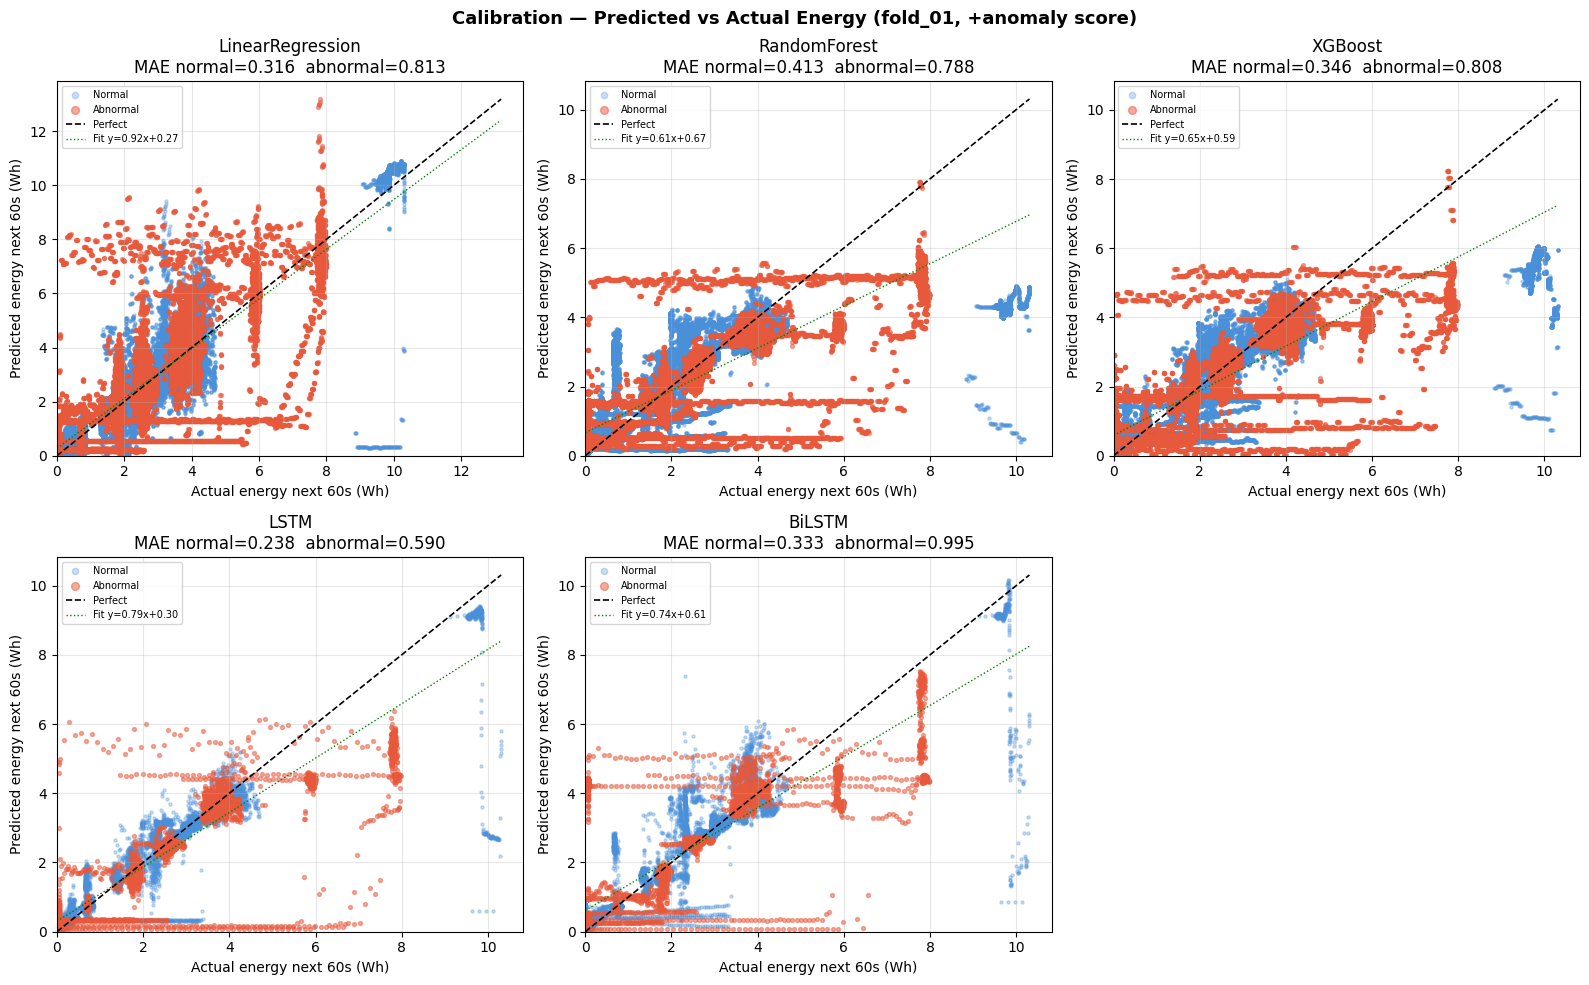

Saved: calibration_predicted_vs_actual.png


<Figure size 640x480 with 0 Axes>

In [17]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

MODELS_PLOT = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']
fold = 'fold_01'  # representative fold
fc_clean = [c for c in enriched[fold]['feature_cols'] if c != 'anomaly_flag']

df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
df_va = enriched[fold]['val']
df_te = enriched[fold]['test']

normal_mask   = df_te['dataset_label'] == 'normal'
abnormal_mask = df_te['dataset_label'] == 'abnormal'

# collect predictions per model — with anomaly score only
all_preds = {}

# tree models
for model_name, mdl_cls, kwargs in [
    ('LinearRegression', LinearRegression, {}),
    ('RandomForest', RandomForestRegressor,
     dict(n_estimators=100, max_depth=15, min_samples_leaf=10,
          max_features=0.5, n_jobs=-1, random_state=42)),
    ('XGBoost', XGBRegressor,
     dict(n_estimators=1000, max_depth=5, learning_rate=0.01,
          min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
          early_stopping_rounds=50, random_state=42, verbosity=0, n_jobs=-1)),
]:
    cols = fc_clean + ['anomaly_score']
    X_tr = df_tr[cols].values.astype(np.float32)
    y_tr = df_tr[TARGET].values.astype(np.float32)
    X_te = df_te[cols].values.astype(np.float32)
    y_te = df_te[TARGET].values.astype(np.float32)

    mdl = mdl_cls(**kwargs)
    if model_name == 'XGBoost':
        X_va = df_va[cols].values.astype(np.float32)
        y_va = df_va[TARGET].values.astype(np.float32)
        mdl.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    else:
        mdl.fit(X_tr, y_tr)

    all_preds[model_name] = {
        'y_true'  : y_te,
        'y_pred'  : mdl.predict(X_te),
        'labels'  : df_te['dataset_label'].values,
    }
    print(f'{model_name} done')

# sequence models — load from saved weights
WINDOW, STRIDE = 50, 10
for arch, bidir in [('LSTM', False), ('BiLSTM', True)]:
    cols   = fc_clean + ['anomaly_score']
    n_feat = len(cols)
    X_te, y_te = make_sequences(df_te, cols, TARGET, WINDOW, STRIDE)

    # rebuild labels aligned to windows
    te_idx = []
    for _, grp in df_te.groupby('log_id', sort=False):
        n = len(grp)
        for i in range(0, n - WINDOW + 1, STRIDE):
            te_idx.append(grp.index[i + WINDOW - 1])
    te_labels = df_te.loc[te_idx, 'dataset_label'].values

    ckpt = OUT_DIR / f'{arch.lower()}_fold_01_anom.pt'
    model = LSTMRegressor(n_feat, hidden=128, layers=2,
                          dropout=0.2, bidirectional=bidir).to(DEVICE)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    model.eval()
    preds = predict_lstm(model, X_te)

    all_preds[arch] = {
        'y_true' : y_te,
        'y_pred' : preds,
        'labels' : te_labels,
    }
    print(f'{arch} done')

# ── plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, model_name in zip(axes, MODELS_PLOT):
    d       = all_preds[model_name]
    y_true  = d['y_true']
    y_pred  = d['y_pred']
    labels  = d['labels']

    norm_mask = labels == 'normal'
    abn_mask  = labels == 'abnormal'

    # scatter normal
    ax.scatter(y_true[norm_mask], y_pred[norm_mask],
               color='#4A90D9', alpha=0.3, s=5, label='Normal')
    # scatter abnormal
    ax.scatter(y_true[abn_mask], y_pred[abn_mask],
               color='#E8593C', alpha=0.5, s=8, label='Abnormal')

    # perfect prediction line
    lim = max(y_true.max(), y_pred.max())
    ax.plot([0, lim], [0, lim], 'k--', lw=1.2, label='Perfect')

    # regression line through all points
    from numpy.polynomial import polynomial as P
    if len(y_true) > 10:
        coef = np.polyfit(y_true, y_pred, 1)
        x_line = np.linspace(0, lim, 100)
        ax.plot(x_line, np.polyval(coef, x_line),
                color='green', lw=1, linestyle=':', label=f'Fit y={coef[0]:.2f}x+{coef[1]:.2f}')

    mae_norm = mean_absolute_error(y_true[norm_mask], y_pred[norm_mask]) if norm_mask.any() else np.nan
    mae_abn  = mean_absolute_error(y_true[abn_mask],  y_pred[abn_mask])  if abn_mask.any()  else np.nan

    ax.set_xlabel('Actual energy next 60s (Wh)')
    ax.set_ylabel('Predicted energy next 60s (Wh)')
    ax.set_title(f'{model_name}\nMAE normal={mae_norm:.3f}  abnormal={mae_abn:.3f}')
    ax.legend(fontsize=7, markerscale=2)
    ax.grid(alpha=0.3)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

# hide unused subplot
axes[-1].set_visible(False)
plt.suptitle('Calibration — Predicted vs Actual Energy (fold_01, +anomaly score)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
plt.savefig(PLOT_DIR / 'calibration_predicted_vs_actual.png', dpi=150, bbox_inches='tight')
print('Saved: calibration_predicted_vs_actual.png')

# abnormal flight subgroup deep dive

In [18]:
# ── 10. Abnormal flight subgroup deep dive ────────────────────────────────────
# For each fold, identify clearly detectable abnormal flights
# (anomaly_score > threshold) and compare MAE with vs without anomaly score

# load OOF + test scores to get per-flight anomaly scores and verdicts
df_scores = pd.read_parquet(
    MODEL_ROOT / 'v3b/07_anomaly_enriched/oof_and_test_anomaly_scores.parquet')

# classify flights by verdict
def get_verdict(score, threshold):
    ratio = score / threshold if threshold > 0 else 0
    if ratio >= 10:  return 'clearly_detectable'
    elif ratio >= 2: return 'marginal'
    else:            return 'indistinguishable'

df_scores['verdict'] = df_scores.apply(
    lambda r: get_verdict(r['anomaly_score'], r['threshold']), axis=1)

print('=== Abnormal flight verdict distribution ===')
abn_scores = df_scores[df_scores['dataset_label'] == 'abnormal']
print(abn_scores.groupby(['fold','verdict']).size().unstack(fill_value=0))
print(f'\nTotal abnormal: {len(abn_scores)}')
print(abn_scores['verdict'].value_counts())

=== Abnormal flight verdict distribution ===
verdict  clearly_detectable  indistinguishable  marginal
fold                                                    
fold_01                   2                  9         2
fold_02                   6                  6         2
fold_03                   4                  8         1
fold_04                   3                 10         0
fold_05                  10                  3         0

Total abnormal: 66
verdict
indistinguishable     36
clearly_detectable    25
marginal               5
Name: count, dtype: int64


In [19]:
# ── per-flight MAE for clearly detectable vs indistinguishable ────────────────
# use tree model (RF) — row-level predictions available directly

fold = 'fold_01'
fc_clean = [c for c in enriched[fold]['feature_cols'] if c != 'anomaly_flag']
df_te    = enriched[fold]['test']
df_tr    = pd.concat([enriched[fold]['train'],
                      enriched[fold]['val']], ignore_index=True)
df_va    = enriched[fold]['val']

# get fold_01 flight verdicts
fold_verdicts = df_scores[
    (df_scores['fold'] == fold) &
    (df_scores['dataset_label'] == 'abnormal')
][['log_id','anomaly_score','threshold','verdict']]

print(f'\nfold_01 abnormal flights:')
print(fold_verdicts[['log_id','anomaly_score','verdict']]\
      .sort_values('anomaly_score', ascending=False).to_string(index=False))


fold_01 abnormal flights:
                              log_id  anomaly_score            verdict
a3363780-8647-4341-a38a-77176235cdf2   2.149147e-03 clearly_detectable
25c37f03-8611-4026-bb3a-ae908b19fb71   3.192870e-04 clearly_detectable
d2dc82d7-0024-4562-b8dc-2edf5e4bbf22   1.577290e-05           marginal
13efd310-a978-497d-8360-cc5b7b4a7d1a   1.269369e-05           marginal
e41b18ed-579a-4b60-9070-c73027d6e388   3.243682e-06  indistinguishable
cb358ec1-2de5-4ff3-97c4-4d02f939cc39   1.975507e-06  indistinguishable
d22e643a-8935-4717-a194-04cc834630fe   1.459192e-06  indistinguishable
16b23126-7342-4d6c-9e76-14c2c6b90a05   4.079118e-07  indistinguishable
fd0f9483-c16c-4b19-bc3e-f61311a29003   3.929778e-07  indistinguishable
7dc86cfe-ebed-400c-939a-ce5decd323ea   3.494866e-07  indistinguishable
597d3d47-5742-4989-b936-d9528edae2a6   3.037563e-07  indistinguishable
39d6eb96-4ef1-41d0-8034-d60fbfe3f456   3.036259e-07  indistinguishable
7f845837-4460-467a-b8a9-f97d8e6eaab4   2.400936e-0


=== Per-flight MAE: baseline vs +anomaly (fold_01 abnormal flights) ===
                              log_id            verdict  anomaly_score  baseline  with_anomaly  delta_MAE  helped
a3363780-8647-4341-a38a-77176235cdf2 clearly_detectable         0.0021    0.0506        0.1874    -0.1368   False
25c37f03-8611-4026-bb3a-ae908b19fb71 clearly_detectable         0.0003    1.2994        1.5751    -0.2757   False
d2dc82d7-0024-4562-b8dc-2edf5e4bbf22           marginal         0.0000    0.3380        0.3311     0.0069    True
13efd310-a978-497d-8360-cc5b7b4a7d1a           marginal         0.0000    1.4420        2.0980    -0.6560   False
cb358ec1-2de5-4ff3-97c4-4d02f939cc39  indistinguishable         0.0000    0.1142        0.2189    -0.1047   False
d22e643a-8935-4717-a194-04cc834630fe  indistinguishable         0.0000    0.3430        0.3693    -0.0263   False
16b23126-7342-4d6c-9e76-14c2c6b90a05  indistinguishable         0.0000    0.3495        0.3864    -0.0369   False
7dc86cfe-ebed-4

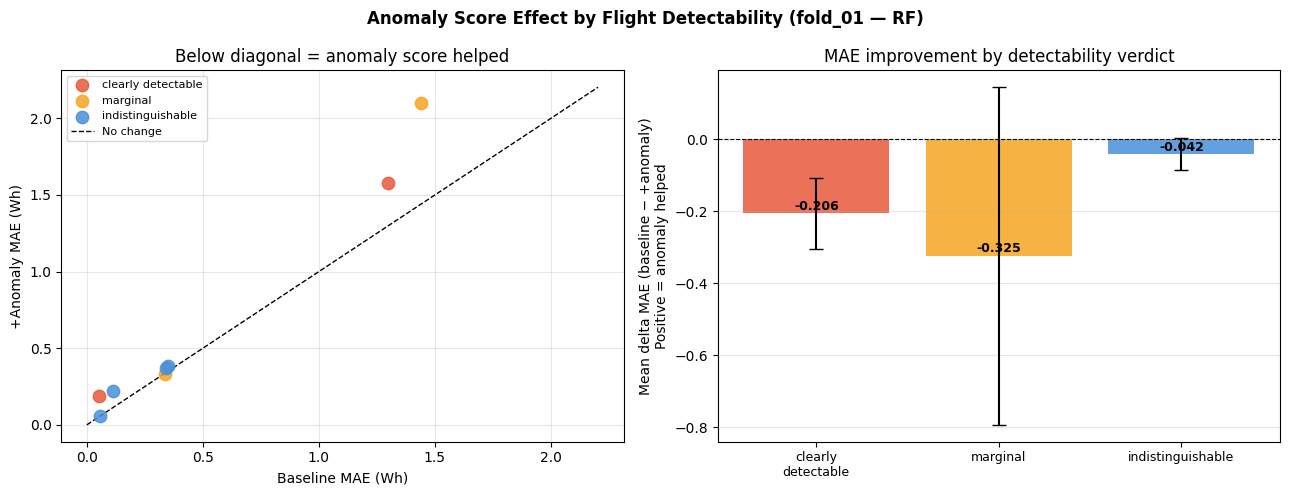

Saved: abnormal_subgroup_deep_dive.png


<Figure size 640x480 with 0 Axes>

In [20]:
# train RF baseline and +anomaly for fold_01
results_per_flight = []

for use_anomaly in [False, True]:
    cols = fc_clean + (['anomaly_score'] if use_anomaly else [])
    X_tr = df_tr[cols].values.astype(np.float32)
    y_tr = df_tr[TARGET].values.astype(np.float32)

    mdl = RandomForestRegressor(n_estimators=100, max_depth=15,
                                min_samples_leaf=10, max_features=0.5,
                                n_jobs=-1, random_state=42)
    mdl.fit(X_tr, y_tr)

    # per-flight MAE on abnormal test flights
    for _, row in fold_verdicts.iterrows():
        fid   = row['log_id']
        grp   = df_te[df_te['log_id'] == fid]
        if grp.empty: continue
        X     = grp[cols].values.astype(np.float32)
        y     = grp[TARGET].values.astype(np.float32)
        preds = mdl.predict(X)
        mae   = mean_absolute_error(y, preds)
        results_per_flight.append({
            'log_id'     : fid,
            'verdict'    : row['verdict'],
            'anomaly_score': row['anomaly_score'],
            'condition'  : 'with_anomaly' if use_anomaly else 'baseline',
            'MAE'        : mae,
        })

df_pf = pd.DataFrame(results_per_flight)

# pivot to compare side by side
df_pivot = df_pf.pivot_table(
    index=['log_id','verdict','anomaly_score'],
    columns='condition', values='MAE'
).reset_index()
df_pivot['delta_MAE'] = df_pivot['baseline'] - df_pivot['with_anomaly']
df_pivot['helped']    = df_pivot['delta_MAE'] > 0
df_pivot = df_pivot.sort_values('anomaly_score', ascending=False)

print('\n=== Per-flight MAE: baseline vs +anomaly (fold_01 abnormal flights) ===')
print(df_pivot[['log_id','verdict','anomaly_score',
                'baseline','with_anomaly','delta_MAE','helped']]\
      .round(4).to_string(index=False))

print('\n=== Mean delta by verdict ===')
print(df_pivot.groupby('verdict')['delta_MAE'].agg(['mean','std','count']).round(4))# ── plot: MAE improvement by verdict ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Anomaly Score Effect by Flight Detectability (fold_01 — RF)',
             fontsize=12, fontweight='bold')

VERDICT_COLORS = {
    'clearly_detectable' : '#E8593C',
    'marginal'           : '#F5A623',
    'indistinguishable'  : '#4A90D9',
}
VERDICT_ORDER = ['clearly_detectable', 'marginal', 'indistinguishable']

# Left: MAE baseline vs +anomaly per flight, coloured by verdict
ax = axes[0]
for v in VERDICT_ORDER:
    sub = df_pivot[df_pivot['verdict'] == v]
    if sub.empty: continue
    x = np.arange(len(sub))
    ax.scatter(sub['baseline'].values, sub['with_anomaly'].values,
               color=VERDICT_COLORS[v], s=80, alpha=0.85,
               label=v.replace('_',' '), zorder=3)

lim = max(df_pivot['baseline'].max(), df_pivot['with_anomaly'].max()) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=1, label='No change')
ax.set_xlabel('Baseline MAE (Wh)')
ax.set_ylabel('+Anomaly MAE (Wh)')
ax.set_title('Below diagonal = anomaly score helped')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Right: delta MAE by verdict (bar)
ax = axes[1]
verdict_means = df_pivot.groupby('verdict')['delta_MAE'].mean()
verdict_stds  = df_pivot.groupby('verdict')['delta_MAE'].std()

bars = []
for i, v in enumerate(VERDICT_ORDER):
    if v not in verdict_means.index: continue
    bar = ax.bar(i, verdict_means[v],
                 color=VERDICT_COLORS[v], alpha=0.85,
                 yerr=verdict_stds.get(v, 0), capsize=5)
    bars.append((i, verdict_means[v]))
    ax.text(i, verdict_means[v] + 0.01,
            f'{verdict_means[v]:+.3f}', ha='center',
            fontsize=9, fontweight='bold')

ax.axhline(0, color='black', lw=0.8, linestyle='--')
ax.set_xticks(range(len(VERDICT_ORDER)))
ax.set_xticklabels([v.replace('_','\n') for v in VERDICT_ORDER], fontsize=9)
ax.set_ylabel('Mean delta MAE (baseline − +anomaly)\nPositive = anomaly helped')
ax.set_title('MAE improvement by detectability verdict')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(PLOT_DIR / 'abnormal_subgroup_deep_dive.png', dpi=150, bbox_inches='tight')
print('Saved: abnormal_subgroup_deep_dive.png')

# per-flight RFT error

In [21]:
# ── 11. Per-flight RFT error ──────────────────────────────────────────────────
# For each test flight compute:
# - actual RFT: total energy remaining / mean active power → seconds
# - predicted RFT: same but using predicted energy
# - RFT error: |actual - predicted| in seconds

fold     = 'fold_01'
fc_clean = [c for c in enriched[fold]['feature_cols'] if c != 'anomaly_flag']
df_te    = enriched[fold]['test']
df_tr    = pd.concat([enriched[fold]['train'],
                      enriched[fold]['val']], ignore_index=True)
df_va    = enriched[fold]['val']

rft_results = []

for use_anomaly in [False, True]:
    cols = fc_clean + (['anomaly_score'] if use_anomaly else [])
    X_tr = df_tr[cols].values.astype(np.float32)
    y_tr = df_tr[TARGET].values.astype(np.float32)

    mdl = RandomForestRegressor(n_estimators=100, max_depth=15,
                                min_samples_leaf=10, max_features=0.5,
                                n_jobs=-1, random_state=42)
    mdl.fit(X_tr, y_tr)

    for fid, grp in df_te.groupby('log_id'):
        grp   = grp.reset_index(drop=True)
        X     = grp[cols].values.astype(np.float32)
        y_true = grp[TARGET].values.astype(np.float32)
        y_pred = mdl.predict(X)

        label  = grp['dataset_label'].iloc[0]

        # active power — use positive power_w rows only
        active_pw = grp[grp['power_w'] > 0]['power_w']
        if len(active_pw) == 0:
            continue
        mean_pw = active_pw.median()  # Wh per second × 3600

        # RFT at each timestep:
        # actual  = target_energy_next_60s / mean_power × 3600 → seconds
        # This gives remaining flight time prediction at each row
        # Use last 10% of flight rows as the "prediction window"
        n       = len(grp)
        start   = int(n * 0.5)  # use second half of flight

        actual_energy  = y_true[start:]
        predict_energy = y_pred[start:]

        actual_rft  = (actual_energy  / mean_pw) * 3600
        predict_rft = (predict_energy / mean_pw) * 3600

        rft_error = np.abs(actual_rft - predict_rft).mean()
        mae_energy = mean_absolute_error(actual_energy, predict_energy)

        # get verdict
        verdict_row = df_scores[
            (df_scores['log_id'] == fid) &
            (df_scores['fold'] == fold)
        ]
        verdict = verdict_row['verdict'].values[0] \
                  if len(verdict_row) > 0 else 'unknown'

        rft_results.append({
            'log_id'       : fid,
            'label'        : label,
            'verdict'      : verdict if label == 'abnormal' else 'normal',
            'condition'    : 'with_anomaly' if use_anomaly else 'baseline',
            'MAE_energy_wh': round(mae_energy, 4),
            'RFT_error_s'  : round(rft_error, 1),
            'mean_power_w' : round(mean_pw, 4),
        })

df_rft_pf = pd.DataFrame(rft_results)

# pivot
df_rft_pivot = df_rft_pf.pivot_table(
    index=['log_id','label','verdict'],
    columns='condition',
    values='RFT_error_s'
).reset_index()
df_rft_pivot['delta_RFT_s'] = df_rft_pivot['baseline'] - df_rft_pivot['with_anomaly']
df_rft_pivot['helped']      = df_rft_pivot['delta_RFT_s'] > 0
df_rft_pivot = df_rft_pivot.sort_values('baseline', ascending=False)

print('=== Per-flight RFT error (seconds) — fold_01 ===')
print(df_rft_pivot[['log_id','label','verdict',
                     'baseline','with_anomaly','delta_RFT_s','helped']]\
      .round(1).to_string(index=False))

print('\n=== Mean RFT error by label ===')
print(df_rft_pf.groupby(['label','condition'])['RFT_error_s']\
      .agg(['mean','std','count']).round(1))

print('\n=== Mean RFT error by verdict ===')
print(df_rft_pf.groupby(['verdict','condition'])['RFT_error_s']\
      .agg(['mean','std','count']).round(1))

df_rft_pivot.to_csv(OUT_DIR / 'per_flight_rft_error.csv', index=False)
print('\nSaved: per_flight_rft_error.csv')

=== Per-flight RFT error (seconds) — fold_01 ===
                              log_id    label            verdict  baseline  with_anomaly  delta_RFT_s  helped
d6b76077-5896-4e81-a966-8e30fd32c323   normal             normal   11277.6       53528.1     -42250.5   False
2cfe94f8-6944-4000-a6a4-f054bea7afc0   normal             normal    9500.5        9891.7       -391.2   False
e4c9925e-ebc8-4e02-aab3-da50ed1f8891   normal             normal    9267.0        8045.3       1221.7    True
72fc1621-863a-4b7f-9d1d-69e5361c4db8   normal             normal    4716.4        4118.7        597.7    True
d22e643a-8935-4717-a194-04cc834630fe abnormal  indistinguishable    4659.0        5192.2       -533.2   False
ec72d5e0-58d4-4474-8a41-0ad214bf21c9   normal             normal    4442.2        5952.1      -1509.9   False
16f11055-fc5c-4f4d-8a9e-a23691b25977   normal             normal    4327.9        3501.0        826.9    True
670aaff6-ba17-4047-ae2c-53e26d74bf74   normal             normal    251

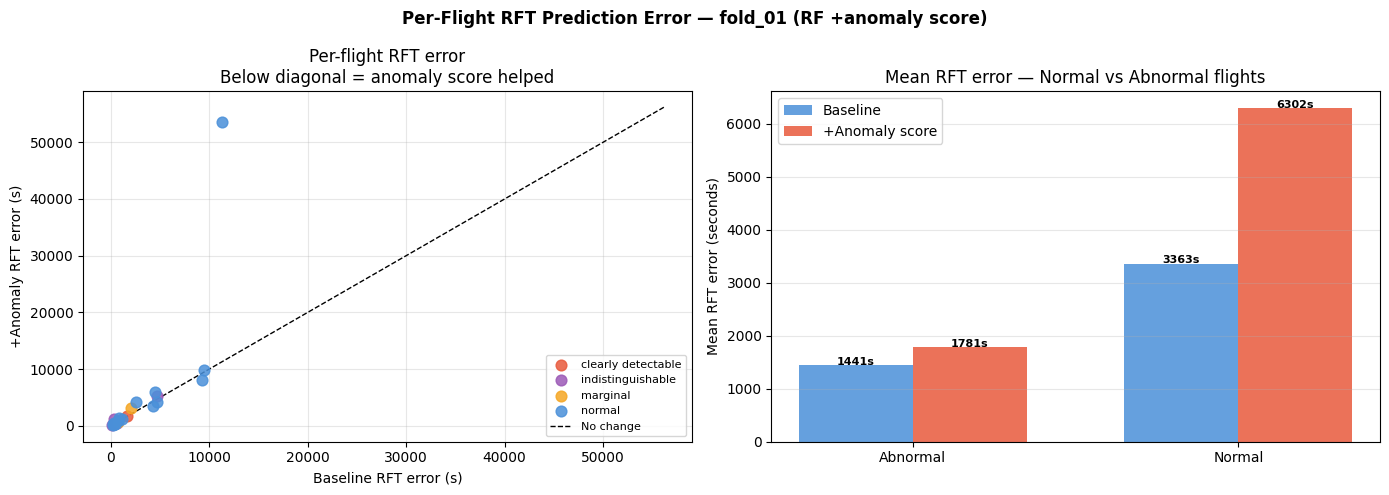

Saved: per_flight_rft_error.png


<Figure size 640x480 with 0 Axes>

In [22]:
# ── plot: per-flight RFT error ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Per-Flight RFT Prediction Error — fold_01 (RF +anomaly score)',
             fontsize=12, fontweight='bold')

VERDICT_COLORS = {
    'clearly_detectable' : '#E8593C',
    'marginal'           : '#F5A623',
    'indistinguishable'  : '#9B59B6',
    'normal'             : '#4A90D9',
}

# Left: scatter baseline vs +anomaly RFT error per flight
ax = axes[0]
for verdict, grp in df_rft_pivot.groupby('verdict'):
    ax.scatter(grp['baseline'], grp['with_anomaly'],
               color=VERDICT_COLORS.get(verdict, 'gray'),
               s=60, alpha=0.85, label=verdict.replace('_',' '), zorder=3)

lim = max(df_rft_pivot['baseline'].max(),
          df_rft_pivot['with_anomaly'].max()) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=1, label='No change')
ax.set_xlabel('Baseline RFT error (s)')
ax.set_ylabel('+Anomaly RFT error (s)')
ax.set_title('Per-flight RFT error\nBelow diagonal = anomaly score helped')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# Right: mean RFT error by label and condition
ax = axes[1]
summary_rft = df_rft_pf.groupby(['label','condition'])['RFT_error_s'].mean().unstack()
labels_plot = summary_rft.index.tolist()
x = np.arange(len(labels_plot))
w = 0.35

for i, cond in enumerate(['baseline', 'with_anomaly']):
    if cond not in summary_rft.columns: continue
    vals = summary_rft[cond].values
    ax.bar(x + (i-0.5)*w, vals, w,
           color='#4A90D9' if cond=='baseline' else '#E8593C',
           alpha=0.85,
           label='Baseline' if cond=='baseline' else '+Anomaly score')
    for xi, v in enumerate(vals):
        ax.text(xi + (i-0.5)*w, v + 5, f'{v:.0f}s',
                ha='center', fontsize=8, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels([l.title() for l in labels_plot])
ax.set_ylabel('Mean RFT error (seconds)')
ax.set_title('Mean RFT error — Normal vs Abnormal flights')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()
plt.savefig(PLOT_DIR / 'per_flight_rft_error.png', dpi=150, bbox_inches='tight')
print('Saved: per_flight_rft_error.png')

# plots

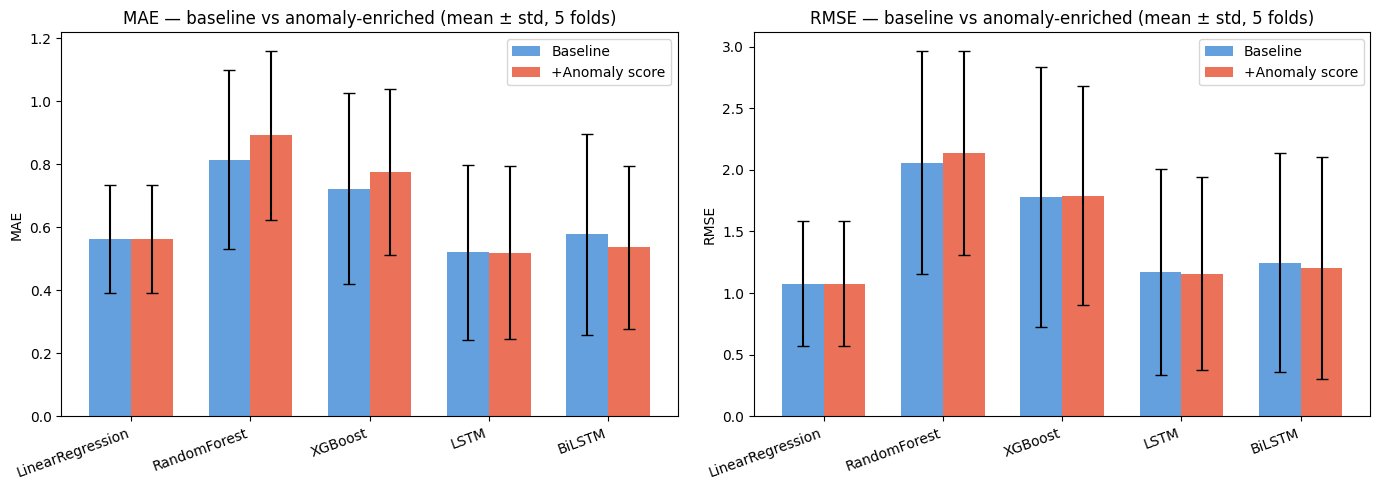

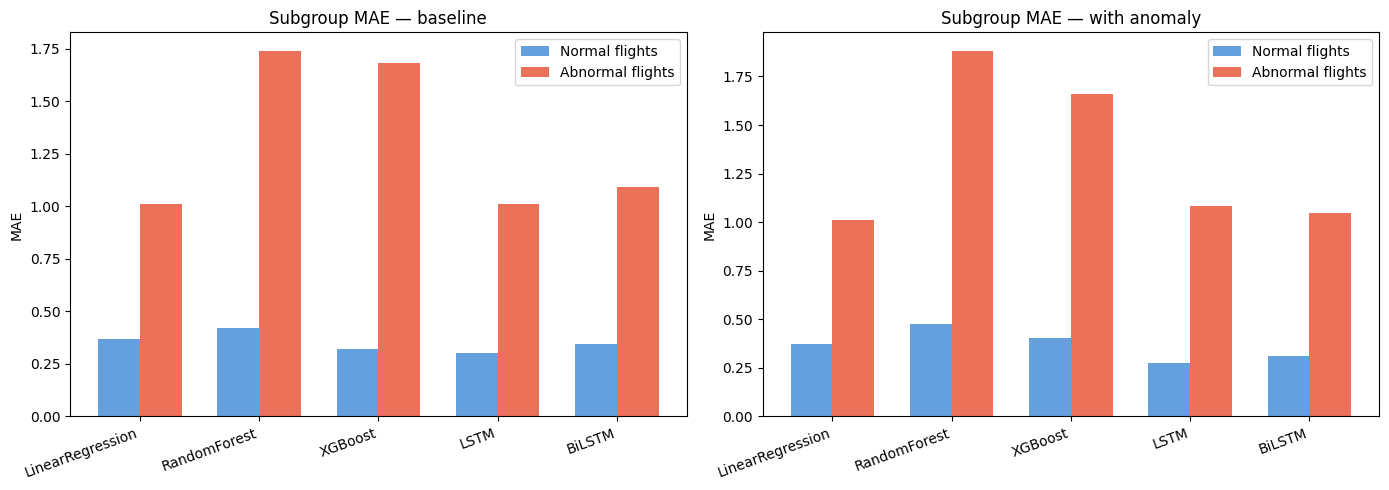

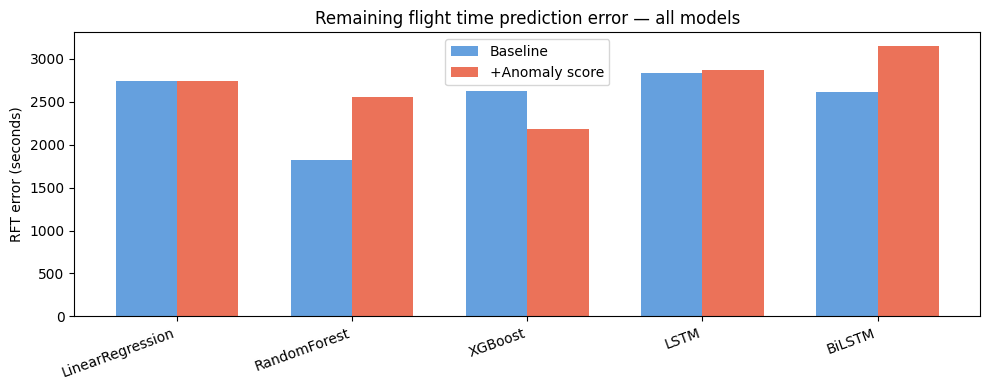

In [23]:
MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']
COLORS = {'baseline': '#4A90D9', 'with_anomaly': '#E8593C'}

# ── Plot 1: MAE with vs without, per model ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    x = np.arange(len(MODELS))
    w = 0.35
    for i, cond in enumerate(['baseline', 'with_anomaly']):
        means = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                                f'{metric}_mean'].values[0]
                 if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
                 else np.nan for m in MODELS]
        stds  = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                                f'{metric}_std'].values[0]
                 if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
                 else np.nan for m in MODELS]
        ax.bar(x + (i-0.5)*w, means, w, yerr=stds, capsize=4,
               color=COLORS[cond], alpha=0.85,
               label='Baseline' if cond == 'baseline' else '+Anomaly score')
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS, rotation=20, ha='right')
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} — baseline vs anomaly-enriched (mean ± std, 5 folds)')
    ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'mae_rmse_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: Normal vs Abnormal MAE subgroup ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cond in zip(axes, ['baseline', 'with_anomaly']):
    sub = df_summary[df_summary['condition'] == cond]
    x   = np.arange(len(MODELS))
    w   = 0.35
    norm_means = [sub.loc[sub['model']==m, 'MAE_normal_mean'].values[0]
                  if len(sub.loc[sub['model']==m]) > 0 else np.nan for m in MODELS]
    abn_means  = [sub.loc[sub['model']==m, 'MAE_abnormal_mean'].values[0]
                  if len(sub.loc[sub['model']==m]) > 0 else np.nan for m in MODELS]
    ax.bar(x - w/2, norm_means, w, color='#4A90D9', alpha=0.85, label='Normal flights')
    ax.bar(x + w/2, abn_means,  w, color='#E8593C', alpha=0.85, label='Abnormal flights')
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS, rotation=20, ha='right')
    ax.set_ylabel('MAE')
    ax.set_title(f'Subgroup MAE — {cond.replace("_"," ")}')
    ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'subgroup_mae_normal_vs_abnormal.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 3: RFT error per model ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(MODELS))
w = 0.35
for i, cond in enumerate(['baseline', 'with_anomaly']):
    rft = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                           'RFT_err_s_mean'].values[0]
           if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
           else np.nan for m in MODELS]
    ax.bar(x + (i-0.5)*w, rft, w,
           color=COLORS[cond], alpha=0.85,
           label='Baseline' if cond == 'baseline' else '+Anomaly score')
ax.set_xticks(x)
ax.set_xticklabels(MODELS, rotation=20, ha='right')
ax.set_ylabel('RFT error (seconds)')
ax.set_title('Remaining flight time prediction error — all models')
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'rft_error_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# SHAP for best tree model

In [24]:
print(X_tr.shape)
print(X_te.shape)

(776094, 17)
(18932, 50, 17)


X_tr shape: (776094, 17)  cols: 17
shap_vals shape: (2000, 17)
cols length    : 17
anomaly_score SHAP rank: 3 of 17


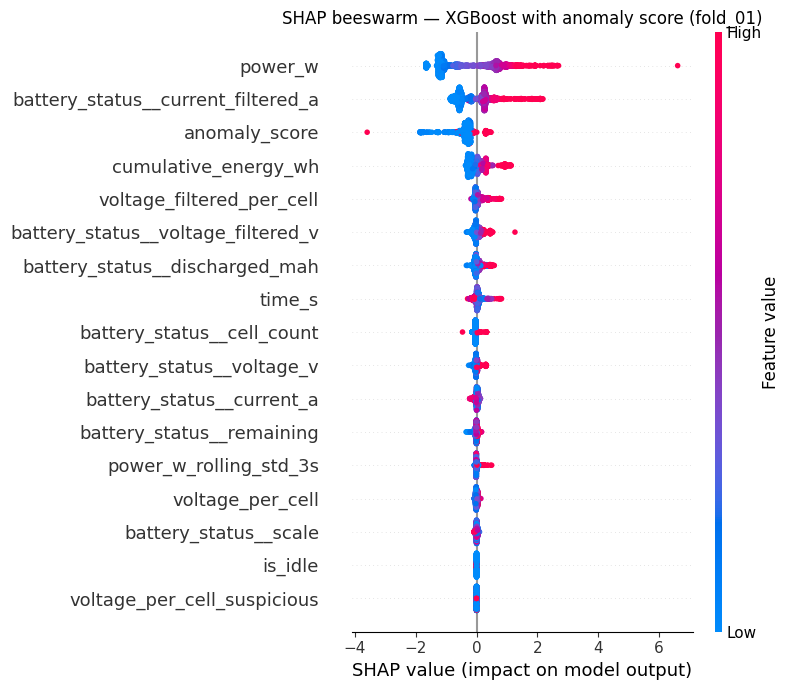

anomaly_score mean |SHAP| — normal  : 0.37127
anomaly_score mean |SHAP| — abnormal: 0.36948


In [25]:
BEST_TREE = 'XGBoost'

fold  = 'fold_01'
fc    = enriched[fold]['feature_cols']
cols  = [c for c in fc if c != 'anomaly_flag'] + ['anomaly_score']  # exclude anomaly_flag
df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
df_va = enriched[fold]['val']
df_te = enriched[fold]['test']

X_tr = df_tr[cols].values.astype(np.float32); y_tr = df_tr[TARGET].values.astype(np.float32)
X_va = df_va[cols].values.astype(np.float32); y_va = df_va[TARGET].values.astype(np.float32)
X_te = df_te[cols].values.astype(np.float32); y_te = df_te[TARGET].values.astype(np.float32)

print(f'X_tr shape: {X_tr.shape}  cols: {len(cols)}')

if BEST_TREE == 'XGBoost':
    mdl = XGBRegressor(n_estimators=1000, max_depth=5, learning_rate=0.01,
                       min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
                       early_stopping_rounds=50, random_state=42, verbosity=0, n_jobs=-1)
    mdl.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    explainer = shap.TreeExplainer(mdl)
else:
    mdl = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=10,
                                max_features=0.5, n_jobs=-1, random_state=42)
    mdl.fit(X_tr, y_tr)
    explainer = shap.TreeExplainer(mdl)

# sample 2000 rows
idx       = np.random.choice(len(X_te), min(2000, len(X_te)), replace=False)
shap_vals = explainer.shap_values(X_te[idx])

print(f'shap_vals shape: {shap_vals.shape}')
print(f'cols length    : {len(cols)}')
assert shap_vals.shape[1] == len(cols), f'Mismatch: {shap_vals.shape[1]} vs {len(cols)}'

# beeswarm
shap.summary_plot(shap_vals, X_te[idx], feature_names=cols,
                  show=False, plot_size=(8, 7))
anom_idx  = cols.index('anomaly_score')
rank      = np.argsort(np.abs(shap_vals).mean(0))[::-1].tolist().index(anom_idx) + 1
print(f'anomaly_score SHAP rank: {rank} of {len(cols)}')
plt.title(f'SHAP beeswarm — {BEST_TREE} with anomaly score (fold_01)')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

# normal vs abnormal SHAP for anomaly_score
normal_idx   = np.where(df_te['dataset_label'].values[idx] == 'normal')[0]
abnormal_idx = np.where(df_te['dataset_label'].values[idx] == 'abnormal')[0]
print(f'anomaly_score mean |SHAP| — normal  : {np.abs(shap_vals[normal_idx, anom_idx]).mean():.5f}')
print(f'anomaly_score mean |SHAP| — abnormal: {np.abs(shap_vals[abnormal_idx, anom_idx]).mean():.5f}')

# per-flight timeline plot

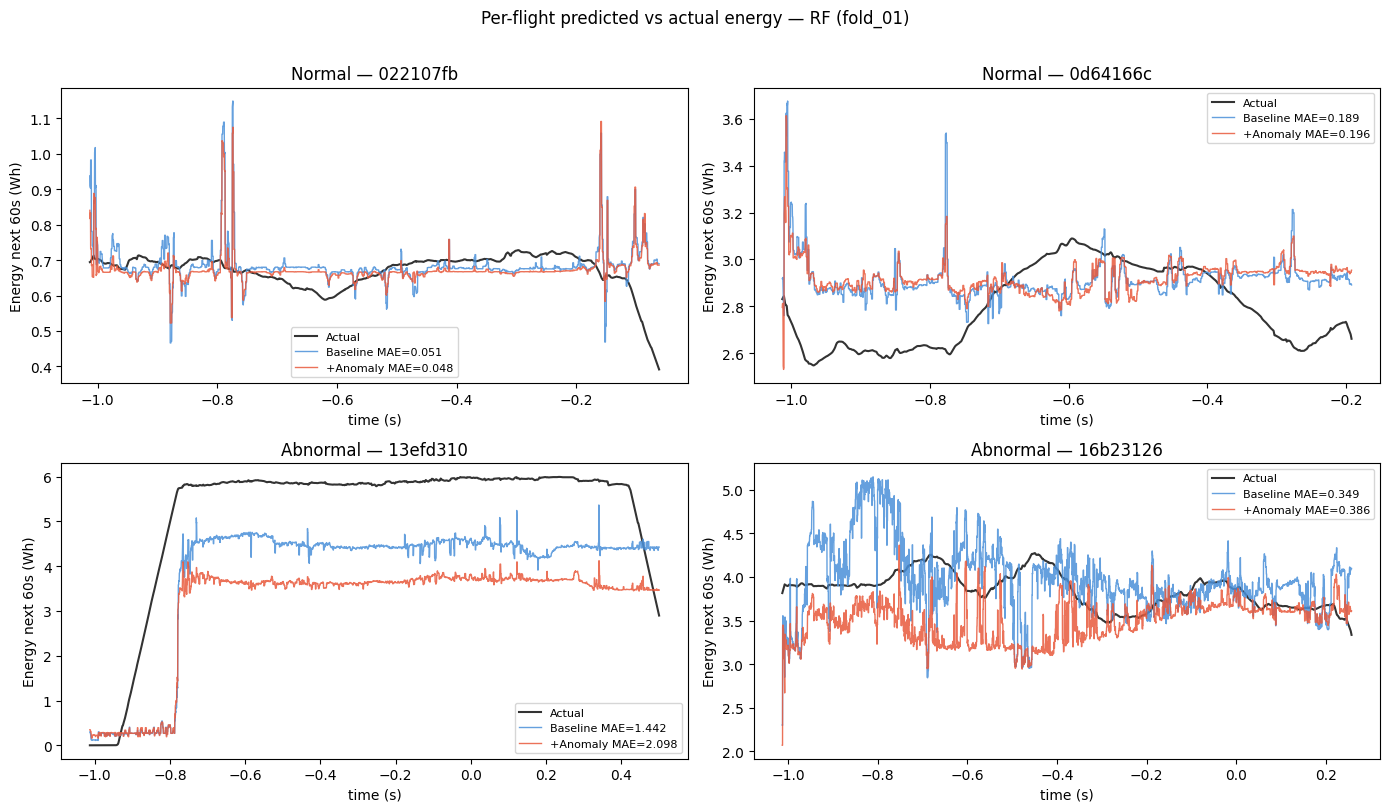

In [26]:
# 2 normal + 2 abnormal flights, best model, with vs without anomaly
fold  = 'fold_01'
fc    = enriched[fold]['feature_cols']
df_te = enriched[fold]['test']

normal_ids   = df_te[df_te['dataset_label'] == 'normal']['log_id'].unique()[:2]
abnormal_ids = df_te[df_te['dataset_label'] == 'abnormal']['log_id'].unique()[:2]
flight_ids   = list(normal_ids) + list(abnormal_ids)
labels       = ['Normal', 'Normal', 'Abnormal', 'Abnormal']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

# refit RF quickly on fold_01 for both conditions
models_plot = {}
df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
df_va = enriched[fold]['val']
for use_anomaly in [False, True]:
    cols = fc + (['anomaly_score'] if use_anomaly else [])
    X_tr, y_tr = get_Xy(df_tr, fc, use_anomaly)
    mdl = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=10,
                                max_features=0.5, n_jobs=-1, random_state=42)
    mdl.fit(X_tr, y_tr)
    models_plot[use_anomaly] = (mdl, cols)

for ax, fid, lbl in zip(axes, flight_ids, labels):
    grp  = df_te[df_te['log_id'] == fid].reset_index(drop=True)
    t    = grp['time_s'].values
    ytrue = grp[TARGET].values
    ax.plot(t, ytrue, 'k-', lw=1.5, label='Actual', alpha=0.8)
    for use_anomaly, color, name in [(False, '#4A90D9', 'Baseline'),
                                      (True,  '#E8593C', '+Anomaly')]:
        mdl, cols = models_plot[use_anomaly]
        X = grp[cols].values.astype(np.float32)
        pred = mdl.predict(X)
        mae  = mean_absolute_error(ytrue, pred)
        ax.plot(t, pred, color=color, lw=1, alpha=0.85, label=f'{name} MAE={mae:.3f}')
    ax.set_title(f'{lbl} — {fid[:8]}')
    ax.set_xlabel('time (s)')
    ax.set_ylabel('Energy next 60s (Wh)')
    ax.legend(fontsize=8)

plt.suptitle('Per-flight predicted vs actual energy — RF (fold_01)', y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'per_flight_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

# final summary

In [27]:
print('=' * 70)
print('NOTEBOOK 08 COMPLETE')
print('=' * 70)

print('\n--- Best model by MAE (with anomaly score) ---')
best = df_summary[df_summary['condition'] == 'with_anomaly'].nsmallest(1, 'MAE_mean')
print(best[['model', 'MAE_mean', 'RMSE_mean', 'R2_mean', 'MAPE_mean', 'RFT_err_s_mean']].to_string(index=False))

print('\n--- Wilcoxon summary ---')
print(df_wilcoxon[['model', 'delta_MAE', 'p_value', 'significant']].to_string(index=False))

print('\n--- Files saved ---')
for f in sorted(OUT_DIR.rglob('*')):
    if f.is_file():
        print(f'  {f.relative_to(OUT_DIR)}')

NOTEBOOK 08 COMPLETE

--- Best model by MAE (with anomaly score) ---
model  MAE_mean  RMSE_mean  R2_mean  MAPE_mean  RFT_err_s_mean
 LSTM  0.518733   1.158927 0.858014 135.736609     2868.249512

--- Wilcoxon summary ---
           model  delta_MAE  p_value  significant
LinearRegression   0.000306  0.03125         True
    RandomForest  -0.076904  1.00000        False
         XGBoost  -0.052243  0.84375        False
            LSTM   0.001556  0.31250        False
          BiLSTM   0.041784  0.21875        False

--- Files saved ---
  ablation_v2_v3_v3b.csv
  all_results.parquet
  all_train_oof_scores.parquet
  anomaly_score_distribution.png
  anomaly_score_global_summary.csv
  anomaly_score_per_fold_split_summary.csv
  anomaly_score_per_fold_summary.csv
  bilstm_fold_01_anom.pt
  bilstm_fold_01_base.pt
  bilstm_fold_02_anom.pt
  bilstm_fold_02_base.pt
  bilstm_fold_03_anom.pt
  bilstm_fold_03_base.pt
  bilstm_fold_04_anom.pt
  bilstm_fold_04_base.pt
  bilstm_fold_05_anom.pt
  bilst